# Part 3: Multimodal Multi-Agent System for Image Understanding and Generation
### DATA 266: Generative Model — Spring 2026

**Goal**: Implement a coordinated multi-agent pipeline:
> Vision Understanding → Prompt Engineering → Image Generation → Critique/Evaluation

| Agent | Task | Marks |
|---|---|---|
| 3.1 Vision Understanding Agent | Caption, objects, scene, VQA | 6 |
| 3.2 Prompt Engineering Agent | Enrich & refine user prompt | 6 |
| 3.3 Image Generation Agent | Text-to-image via Stable Diffusion | 6 |
| 3.4 Critique & Evaluation Agent | CLIP score + rubric + verdict | 6 |
| 3.5 Integration & Execution | Full orchestrated pipeline, 3 use cases | 6 |


## Section 0 — Setup & Configuration

In [1]:
# -- Install dependencies (run once) --
import subprocess, sys
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "google-genai", "diffusers>=0.27.0", "transformers>=4.40.0",
     "torch", "torchvision", "Pillow", "accelerate", "python-dotenv",
     "requests", "matplotlib"],
    check=True
)
print("Dependencies installed.")

Dependencies installed.


In [2]:
import os
import sys
import json
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import requests
import torch

warnings.filterwarnings('ignore')

# Add Part_3 root to path so agents/ package is importable
ROOT = Path('.').resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(f"Working directory : {ROOT}")
print(f"PyTorch version   : {torch.__version__}")
print(f"CUDA available    : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU               : {torch.cuda.get_device_name(0)}")

Working directory : C:\Users\018315986\Desktop\Genai\Lab 2\Part_3
PyTorch version   : 2.11.0+cu128
CUDA available    : True
GPU               : NVIDIA GeForce RTX 5090


In [3]:
# ── API Key Configuration ───────────────────────────────────────────────────
# Method 1: set directly here (ONLY for local use — do NOT commit to git)
# GOOGLE_API_KEY = "AIza..."

# Method 2 (recommended): load from .env file
try:
    from dotenv import load_dotenv
    load_dotenv()  # reads .env in Part_3/
except ImportError:
    pass

GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY", "")

# ── If you don't have a key set, enter it here ──────────────────────────────
if not GOOGLE_API_KEY:
    GOOGLE_API_KEY = input("Enter your Google Gemini API key: ").strip()
    os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY

print(f"API key configured: {'  YES' if GOOGLE_API_KEY else ' MISSING'}")

API key configured:   YES


  Already exists: use_case_1_landscape.jpg
  Already exists: use_case_2_cityscape.jpg
  Already exists: use_case_3_portrait.jpg


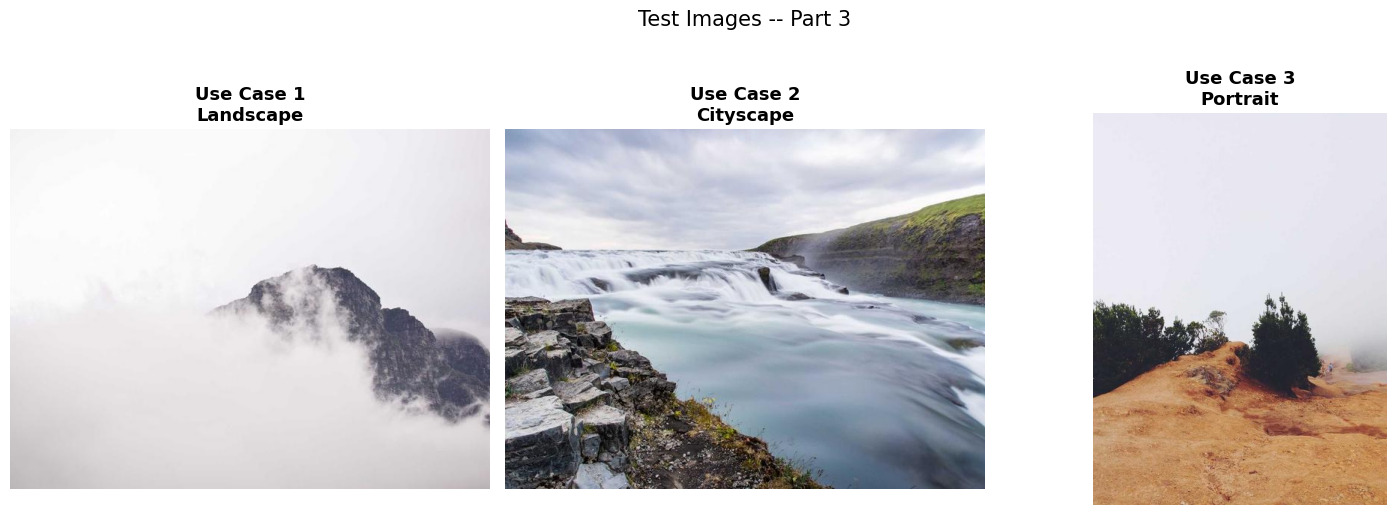

In [4]:
# -- Download 3 test images (picsum.photos - no rate limits) --
TEST_IMAGES_DIR = ROOT / "test_images"
TEST_IMAGES_DIR.mkdir(exist_ok=True)
OUTPUTS_DIR = ROOT / "outputs"
OUTPUTS_DIR.mkdir(exist_ok=True)

IMAGE_URLS = [
    ("use_case_1_landscape.jpg",  "https://picsum.photos/seed/landscape/640/480"),
    ("use_case_2_cityscape.jpg",   "https://picsum.photos/seed/city42/640/480"),
    ("use_case_3_portrait.jpg",    "https://picsum.photos/seed/portrait7/480/640"),
]

for fname, url in IMAGE_URLS:
    fpath = TEST_IMAGES_DIR / fname
    if not fpath.exists():
        print(f"Downloading {fname} ...")
        r = requests.get(url, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
        r.raise_for_status()
        with open(fpath, "wb") as fh:
            fh.write(r.content)
        print(f"  Saved -> {fpath}")
    else:
        print(f"  Already exists: {fname}")

TEST_IMAGE_PATHS = [TEST_IMAGES_DIR / fname for fname, _ in IMAGE_URLS]

# Preview all 3 test images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
labels = ["Use Case 1\nLandscape", "Use Case 2\nCityscape", "Use Case 3\nPortrait"]
for ax, path, label in zip(axes, TEST_IMAGE_PATHS, labels):
    ax.imshow(Image.open(path))
    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.axis("off")
plt.suptitle("Test Images -- Part 3", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

---
## Section 1 — Agent 3.1: Vision Understanding Agent

**Task**: Analyze an input image and extract key visual information using Google Gemini 1.5 Flash.

**Outputs**:
- Short image caption
- List of key objects/entities
- Brief scene description  
- Answers to ≥2 visual questions

In [5]:
from agents.vision_agent import VisionUnderstandingAgent

vision_agent = VisionUnderstandingAgent(api_key=GOOGLE_API_KEY)
print(f"Vision Agent initialized  →  model: {vision_agent.model_name}")

[VisionAgent] Auto-discovered model: gemini-2.5-flash
Vision Agent initialized  →  model: gemini-2.5-flash


In [6]:
# ── Demo on Use Case 1: Tundra Landscape ────────────────────────────────────
DEMO_IMAGE = TEST_IMAGE_PATHS[0]  # use_case_1_landscape.jpg

CUSTOM_QUESTIONS = [
    "Is there any human presence or man-made structure visible?",
    "What time of day does this image appear to depict?",
]

vision_output_1 = vision_agent.analyze(
    image_path=DEMO_IMAGE,
    visual_questions=CUSTOM_QUESTIONS,
)

[VisionAgent] Analysing 'use_case_1_landscape.jpg' with gemini-2.5-flash ...

VISION UNDERSTANDING AGENT -- OUTPUT
Caption  : A majestic mountain peak partially emerges from a dense blanket of white clouds and fog under an overcast sky.
Objects  : Mountain, clouds, fog, rock, sky
Scene    : The scene captures a rugged mountain, whose dark, textured rock faces are partially visible through thick white clouds and mist. The overcast, light grey sky merges with the atmospheric fog, enveloping the upper half of the mountain. The overall impression is one of a serene, natural landscape shrouded in a mystical, ethereal atmosphere.

Visual Q&A:
  Q: Is there any human presence or man-made structure visible?
  A: No, there is no human presence or man-made structure visible.
  Q: What time of day does this image appear to depict?
  A: This image appears to depict daytime, likely under overcast or misty conditions.



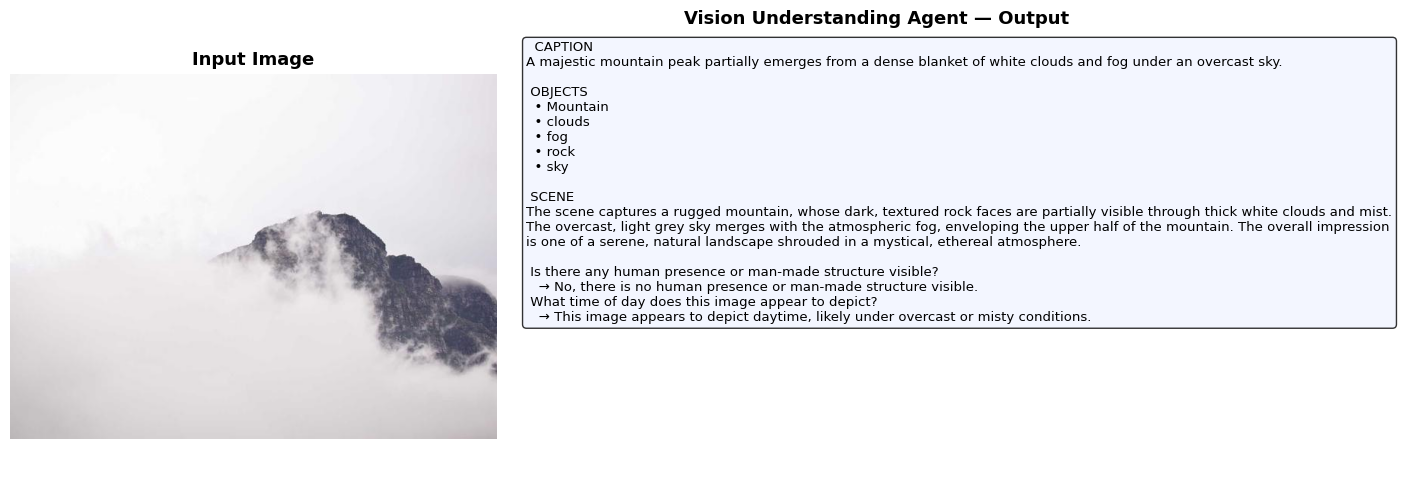

Figure saved → outputs/vision_agent_demo.png


In [7]:
# ── Display results side-by-side with the image ──────────────────────────────
fig, (ax_img, ax_txt) = plt.subplots(1, 2, figsize=(14, 5),
                                      gridspec_kw={'width_ratios': [1, 1.5]})

ax_img.imshow(Image.open(DEMO_IMAGE))
ax_img.set_title("Input Image", fontsize=13, fontweight='bold')
ax_img.axis('off')

summary = (
    f"  CAPTION\n{vision_output_1['caption']}\n\n"
    f" OBJECTS\n" + "\n".join(f"  • {o}" for o in vision_output_1['objects']) + "\n\n"
    f" SCENE\n{vision_output_1['scene_description']}\n\n"
    + "\n".join(
        f" {item['question']}\n   → {item['answer']}"
        for item in vision_output_1['vqa']
    )
)
ax_txt.text(0.02, 0.98, summary, transform=ax_txt.transAxes,
            fontsize=9.5, va='top', ha='left', wrap=True,
            bbox=dict(boxstyle='round', facecolor='#f0f4ff', alpha=0.8))
ax_txt.set_title("Vision Understanding Agent — Output", fontsize=13, fontweight='bold')
ax_txt.axis('off')

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "vision_agent_demo.png", dpi=120, bbox_inches='tight')
plt.show()
print("Figure saved → outputs/vision_agent_demo.png")

---
## Section 2 — Agent 3.2: Prompt Engineering Agent

**Task**: Refine the user's instruction into a richer, clearer generation prompt.

- Rewrites the prompt clearly  
- Enriches it with visual details from the Vision Agent  
- Preserves the intended transformation type

In [8]:
from agents.prompt_agent import PromptEngineeringAgent

prompt_agent = PromptEngineeringAgent(api_key=GOOGLE_API_KEY)
print(f"Prompt Agent initialized  →  model: {prompt_agent.model_name}")

[PromptAgent] Auto-discovered model: gemini-2.5-flash
Prompt Agent initialized  →  model: gemini-2.5-flash


In [9]:
# ── Demo: Refine user instruction using vision context ───────────────────────
USER_INSTRUCTION_1 = "Transform this landscape into a dramatic oil painting"

prompt_output_1 = prompt_agent.refine(
    user_instruction=USER_INSTRUCTION_1,
    vision_output=vision_output_1,
)

[PromptAgent] Refining user instruction with gemini-2.5-flash ...

PROMPT ENGINEERING AGENT -- OUTPUT
Original : Transform this landscape into a dramatic oil painting

Refined Prompt:
  A dramatic oil painting depicting a majestic, rugged mountain peak. Dark, textured rock faces powerfully emerge from a dense blanket of thick, white, ethereal clouds and mist. An overcast, light grey sky seamlessly merges with the atmospheric fog, creating a serene yet profoundly dramatic and mystical landscape, devoid of human presence or structures. Daytime.

Transformation Type: stylization

Enrichment Notes:
  - Integrated specific details like "rugged" and "dark, textured rock faces" to enhance the mountain's description.
  - Emphasized "thick, white, ethereal clouds and mist" to capture the mystical, atmospheric quality.
  - Clarified the "overcast, light grey sky" merging with "atmospheric fog" for a cohesive and dramatic setting.



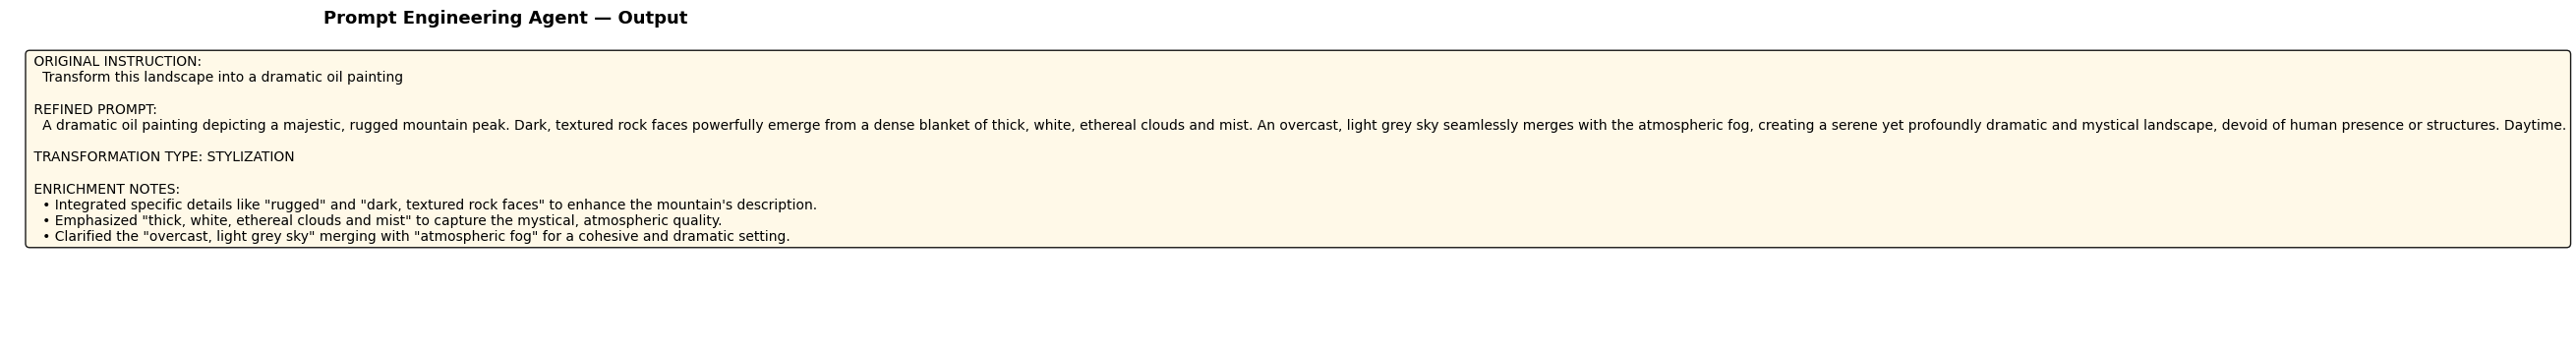

In [10]:
# ── Visualise the refinement ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 4))
ax.axis('off')

content = (
    f" ORIGINAL INSTRUCTION:\n   {prompt_output_1['original_instruction']}\n\n"
    f" REFINED PROMPT:\n   {prompt_output_1['refined_prompt']}\n\n"
    f" TRANSFORMATION TYPE: {prompt_output_1['transformation_type'].upper()}\n\n"
    f" ENRICHMENT NOTES:\n"
    + "\n".join(f"   • {n}" for n in prompt_output_1['enrichment_notes'])
)
ax.text(0.02, 0.95, content, transform=ax.transAxes, fontsize=10,
        va='top', ha='left',
        bbox=dict(boxstyle='round', facecolor='#fff9e6', alpha=0.9))
ax.set_title("Prompt Engineering Agent — Output", fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "prompt_agent_demo.png", dpi=120, bbox_inches='tight')
plt.show()

---
## Section 3 — Agent 3.3: Image Generation Agent

**Task**: Generate a new image from the refined prompt using Stable Diffusion 1.5.

> ⚠️ **Note**: First run downloads ~4GB model weights from HuggingFace. Subsequent runs use the local cache.
> - **GPU (CUDA)**: ~20–45 seconds  
> - **CPU**: ~2–3 minutes

In [11]:
from agents.generation_agent import ImageGenerationAgent

gen_agent = ImageGenerationAgent(
    output_dir=OUTPUTS_DIR,
    num_inference_steps=25,   # 25 = fast; increase to 50 for higher quality
    guidance_scale=7.5,
)
print(f"Generation Agent initialized  →  device: {gen_agent.device.upper()}")

[GenerationAgent] Device: CUDA
Generation Agent initialized  →  device: CUDA


In [12]:
# ── Generate image from the refined prompt ───────────────────────────────────
gen_output_1 = gen_agent.generate(
    refined_prompt=prompt_output_1["refined_prompt"],
    mode=prompt_output_1["transformation_type"],
    seed=42,  # fixed seed for reproducibility
)

[GenerationAgent] Loading model 'runwayml/stable-diffusion-v1-5' …


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 2873.63it/s]1.15s/it]
CLIPTextModel LOAD REPORT from: C:\Users\018315986\.cache\huggingface\hub\models--runwayml--stable-diffusion-v1-5\snapshots\451f4fe16113bff5a5d2269ed5ad43b0592e9a14\text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading pipeline components...: 100%|██████████| 6/6 [00:01<00:00,  3.92it/s]


[GenerationAgent] Model loaded and ready.
[GenerationAgent] Generating 1 image(s) [mode=stylization, steps=25, seed=42] …


100%|██████████| 25/25 [00:01<00:00, 19.19it/s]


  Saved: C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_stylization_20260422_124828_0.png
[GenerationAgent] Done in 1.6s. Metadata → C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_stylization_20260422_124828_meta.json


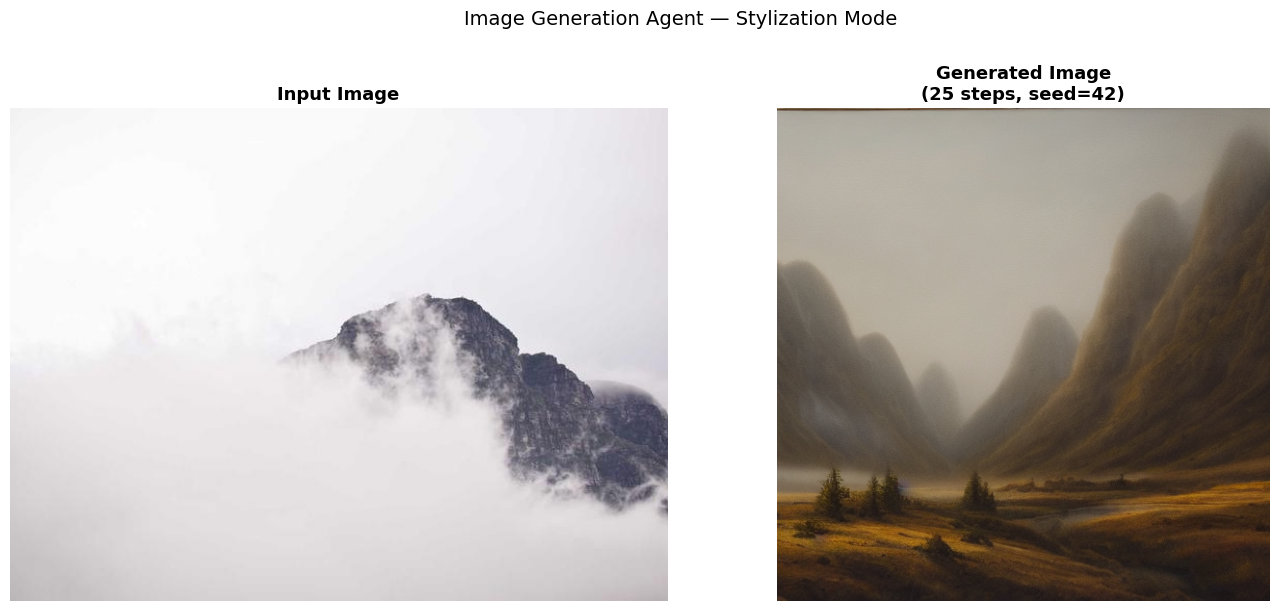


Generation metadata:
  prompt                   : A dramatic oil painting depicting a majestic, rugged mountain peak. Dark, textured rock faces powerfully emerge from a dense blanket of thick, white, ethereal clouds and mist. An overcast, light grey sky seamlessly merges with the atmospheric fog, creating a serene yet profoundly dramatic and mystical landscape, devoid of human presence or structures. Daytime.
  negative_prompt          : blurry, low quality, watermark, text, ugly, disfigured, bad anatomy, extra limbs
  model_id                 : runwayml/stable-diffusion-v1-5
  num_inference_steps      : 25
  guidance_scale           : 7.5
  seed                     : 42
  device                   : cuda
  mode                     : stylization
  num_images               : 1
  generation_time_s        : 1.6


In [13]:
# ── Show input vs generated side-by-side ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(Image.open(DEMO_IMAGE))
axes[0].set_title("Input Image", fontsize=13, fontweight='bold')
axes[0].axis('off')

generated_path_1 = gen_output_1["output_paths"][0]
axes[1].imshow(Image.open(generated_path_1))
axes[1].set_title(
    f"Generated Image\n({gen_output_1['metadata']['num_inference_steps']} steps, "
    f"seed={gen_output_1['metadata']['seed']})",
    fontsize=13, fontweight='bold'
)
axes[1].axis('off')

plt.suptitle(f"Image Generation Agent — {gen_output_1['mode'].title()} Mode",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "generation_agent_demo.png", dpi=120, bbox_inches='tight')
plt.show()

print(f"\nGeneration metadata:")
for k, v in gen_output_1['metadata'].items():
    print(f"  {k:<25}: {v}")

---
## Section 4 — Agent 3.4: Critique and Evaluation Agent

**Task**: Evaluate the generated image against the input and prompt.

**Automatic signal**: CLIP cosine similarity (prompt ↔ image, image ↔ image)  
**Qualitative critique**: Gemini 1.5 Flash comparing both images  
**Verdict**: `accept` or `revise`

In [14]:
from agents.evaluation_agent import CritiqueEvaluationAgent

eval_agent = CritiqueEvaluationAgent(api_key=GOOGLE_API_KEY)
print(f"Evaluation Agent initialized  →  CLIP model: {eval_agent.clip_model_id}")

[EvalAgent] Auto-discovered model: gemini-2.5-flash
Evaluation Agent initialized  →  CLIP model: openai/clip-vit-base-patch32


In [15]:
# ── Evaluate use case 1 ──────────────────────────────────────────────────────
eval_output_1 = eval_agent.evaluate(
    input_image_path=DEMO_IMAGE,
    generated_image_path=generated_path_1,
    refined_prompt=prompt_output_1["refined_prompt"],
)

[EvalAgent] Loading CLIP model 'openai/clip-vit-base-patch32' ...


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 33619.31it/s]
CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[EvalAgent] CLIP ready.
[EvalAgent] Computing CLIP similarity (prompt <-> generated image) ...
[EvalAgent] Computing image-to-image CLIP similarity ...

CRITIQUE & EVALUATION AGENT -- OUTPUT
CLIP (prompt <-> image) : 0.5796
Image-to-image sim     : 0.8462

Rubric Scores (each /5):
  Visual Relevance            : 5/5
  Prompt Faithfulness         : 5/5
  Transformation Quality      : 5/5
  Overall Aesthetic           : 5/5
Rubric Total           : 20.0/20

Verdict  : ACCEPT

Critique :
The generated image applies an oil painting style to a mountainous landscape, retaining a general sense of mist and geological features from the source. However, it fails to fully embody the prompt's core elements: the mountains recede into a warmer, more diffuse haze rather than having "dark, textured rock faces powerfully emerge from a dense blanket of thick, white, ethereal clouds and mist." The composition shifts from a singular peak to a wider valley view, and the implied stark, dramatic atmosphere i

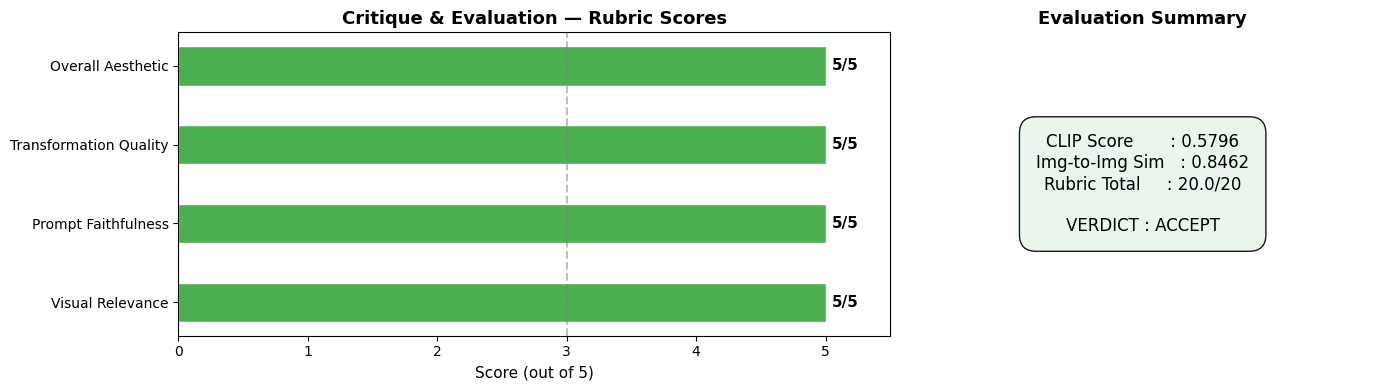

In [16]:
# ── Rubric scorecard visualization ──────────────────────────────────────────
criteria = list(eval_output_1['rubric_scores'].keys())
scores = list(eval_output_1['rubric_scores'].values())
colors = ['#4CAF50' if s >= 4 else '#FFC107' if s >= 3 else '#F44336' for s in scores]

fig, (ax_bar, ax_info) = plt.subplots(1, 2, figsize=(14, 4),
                                       gridspec_kw={'width_ratios': [1.5, 1]})

bars = ax_bar.barh(criteria, scores, color=colors, edgecolor='white', height=0.5)
ax_bar.set_xlim(0, 5.5)
ax_bar.set_xlabel("Score (out of 5)", fontsize=11)
ax_bar.set_title("Critique & Evaluation — Rubric Scores", fontsize=13, fontweight='bold')
ax_bar.axvline(x=3, color='gray', linestyle='--', alpha=0.5, label='Threshold=3')
for bar, s in zip(bars, scores):
    ax_bar.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f"{s}/5", va='center', fontsize=11, fontweight='bold')

summary_text = (
    f"CLIP Score       : {eval_output_1['clip_score']:.4f}\n"
    f"Img-to-Img Sim   : {eval_output_1['image_to_image_similarity']:.4f}\n"
    f"Rubric Total     : {eval_output_1['rubric_total']}/20\n\n"
    f"VERDICT : {eval_output_1['verdict'].upper()}"
)
verdict_color = '#e8f5e9' if eval_output_1['verdict'] == 'accept' else '#fce4ec'
ax_info.text(0.5, 0.5, summary_text, transform=ax_info.transAxes,
             fontsize=12, va='center', ha='center',
             bbox=dict(boxstyle='round,pad=1', facecolor=verdict_color, alpha=0.9))
ax_info.set_title("Evaluation Summary", fontsize=13, fontweight='bold')
ax_info.axis('off')

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "evaluation_agent_demo.png", dpi=120, bbox_inches='tight')
plt.show()

In [17]:
# ── Print full critique text ────────────────────────────────────────────────
print("Qualitative Critique from Gemini:\n")
print(eval_output_1['critique_text'])

Qualitative Critique from Gemini:

The generated image applies an oil painting style to a mountainous landscape, retaining a general sense of mist and geological features from the source. However, it fails to fully embody the prompt's core elements: the mountains recede into a warmer, more diffuse haze rather than having "dark, textured rock faces powerfully emerge from a dense blanket of thick, white, ethereal clouds and mist." The composition shifts from a singular peak to a wider valley view, and the implied stark, dramatic atmosphere is replaced by a softer, warmer palette. While visually relevant in subject, the transformation significantly misses crucial atmospheric and compositional details specified in the prompt.

VERDICT: revise
Reason: Fails to faithfully depict the "dark, textured rock faces powerfully emerging from a dense blanket of thick, white, ethereal clouds and mist" as requested.


---
## Section 5 — Agent 3.5: Integration and Execution

Run the **full orchestrated pipeline** on **3 use cases**:

| Use Case | Image | Instruction | Mode |
|---|---|---|---|
| 1 | Tundra landscape | Oil painting transformation | stylization |
| 2 | NYC / Central Park | Anime style conversion | stylization |
| 3 | Mona Lisa portrait | Cyberpunk enhancement | enhancement |

In [18]:
from orchestrator import MultiAgentOrchestrator

orchestrator = MultiAgentOrchestrator(
    api_key=GOOGLE_API_KEY,
    output_dir=OUTPUTS_DIR,
    gen_steps=25,
)
print("Orchestrator initialized — all 4 agents ready.")

[VisionAgent] Auto-discovered model: gemini-2.5-flash
[PromptAgent] Auto-discovered model: gemini-2.5-flash
[GenerationAgent] Device: CUDA
[EvalAgent] Auto-discovered model: gemini-2.5-flash
Orchestrator initialized — all 4 agents ready.


In [19]:
# ── Define the 3 use cases ───────────────────────────────────────────────────
USE_CASES = [
    {
        "image_path": TEST_IMAGE_PATHS[0],          # Tundra landscape
        "user_instruction": "Transform this into a dramatic oil painting with rich warm tones",
        "mode": "stylization",
        "visual_questions": [
            "What natural elements dominate the scene?",
            "Is the lighting golden hour, overcast, or harsh sunlight?",
        ],
        "seed": 42,
    },
    {
        "image_path": TEST_IMAGE_PATHS[1],          # NYC / Central Park
        "user_instruction": "Convert this cityscape scene into anime art style",
        "mode": "stylization",
        "visual_questions": [
            "Are there trees or greenery visible in the scene?",
            "What architectural features stand out most prominently?",
        ],
        "seed": 123,
    },
    {
        "image_path": TEST_IMAGE_PATHS[2],          # Mona Lisa portrait
        "user_instruction": "Reimagine this portrait with a cyberpunk neon-lit futuristic enhancement",
        "mode": "enhancement",
        "visual_questions": [
            "Describe the expression and posture of the subject.",
            "What is the background setting like in this portrait?",
        ],
        "seed": 999,
    },
]

print(f"Prepared {len(USE_CASES)} use cases.")

Prepared 3 use cases.


In [20]:
# ── Run the full pipeline on all 3 use cases ─────────────────────────────────
all_results = orchestrator.run_batch(USE_CASES)


════════════════════════════════════════════════════════════
  USE CASE 1/3
════════════════════════════════════════════════════════════

>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
>         PIPELINE RUN : use_case_1_landscape.jpg          >
>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>

── STEP 1/4  Vision Understanding ──────────────────────
[VisionAgent] Analysing 'use_case_1_landscape.jpg' with gemini-2.5-flash ...

VISION UNDERSTANDING AGENT -- OUTPUT
Caption  : A rugged mountain peak is partially visible, shrouded in thick white fog under an overcast sky.
Objects  : Mountain, fog, clouds, sky, rock formations, vegetation
Scene    : The image displays a majestic, dark mountain range partially obscured by a vast expanse of dense, white fog or clouds. The upper sections of the mountain peaks, characterized by their textured rock faces and hints of sparse vegetation, emerge dramatically from the ethereal mist. The sky above is uniformly bright and li

100%|██████████| 25/25 [00:01<00:00, 21.37it/s]


  Saved: C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_stylization_20260422_124857_0.png
[GenerationAgent] Done in 1.3s. Metadata → C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_stylization_20260422_124857_meta.json
── STEP 4/4  Critique & Evaluation ────────────────────
[EvalAgent] Loading CLIP model 'openai/clip-vit-base-patch32' ...


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 30112.80it/s]
CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[EvalAgent] CLIP ready.
[EvalAgent] Computing CLIP similarity (prompt <-> generated image) ...
[EvalAgent] Computing image-to-image CLIP similarity ...

CRITIQUE & EVALUATION AGENT -- OUTPUT
CLIP (prompt <-> image) : 0.5837
Image-to-image sim     : 0.8473

Rubric Scores (each /5):
  Visual Relevance            : 5/5
  Prompt Faithfulness         : 5/5
  Transformation Quality      : 5/5
  Overall Aesthetic           : 5/5
Rubric Total           : 20.0/20

Verdict  : ACCEPT

Critique :
The generated image drastically alters the scene from the original, shifting from a singular, fog-shrouded peak to a vast mountain range bathed in golden light. While both depict mountains, the compositional focus and overall atmosphere are fundamentally different, despite a high similarity score. The prompt's artistic style, warm tones, amber lighting, and impasto brushstrokes are well-represented in Image 2. However, a crucial prompt element—"dark, textured peaks majestically emerging from a vast expans

100%|██████████| 25/25 [00:01<00:00, 20.01it/s]


  Saved: C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_stylization_20260422_124923_0.png
[GenerationAgent] Done in 1.4s. Metadata → C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_stylization_20260422_124923_meta.json
── STEP 4/4  Critique & Evaluation ────────────────────
[EvalAgent] Computing CLIP similarity (prompt <-> generated image) ...
[EvalAgent] Computing image-to-image CLIP similarity ...

CRITIQUE & EVALUATION AGENT -- OUTPUT
CLIP (prompt <-> image) : 0.5796
Image-to-image sim     : 0.9129

Rubric Scores (each /5):
  Visual Relevance            : 5/5
  Prompt Faithfulness         : 5/5
  Transformation Quality      : 5/5
  Overall Aesthetic           : 5/5
Rubric Total           : 20.0/20

Verdict  : ACCEPT

Critique :
The generated image significantly deviates from the source, transforming its wide, open multi-tiered waterfall and sky into a more enclosed forest river with smaller cascades. Prompt faithfulness is low, as it fails to depict a "majestic,

100%|██████████| 25/25 [00:01<00:00, 20.71it/s]


  Saved: C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_enhancement_20260422_125001_0.png
[GenerationAgent] Done in 1.3s. Metadata → C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\gen_enhancement_20260422_125001_meta.json
── STEP 4/4  Critique & Evaluation ────────────────────
[EvalAgent] Computing CLIP similarity (prompt <-> generated image) ...
[EvalAgent] Computing image-to-image CLIP similarity ...

CRITIQUE & EVALUATION AGENT -- OUTPUT
CLIP (prompt <-> image) : 0.5892
Image-to-image sim     : 0.7916

Rubric Scores (each /5):
  Visual Relevance            : 4/5
  Prompt Faithfulness         : 5/5
  Transformation Quality      : 5/5
  Overall Aesthetic           : 5/5
Rubric Total           : 19.0/20

Verdict  : ACCEPT

Critique :
The generated image showcases a remarkable transformation, converting the natural landscape of Image 1 into a vibrant cyberpunk portrait while maintaining significant structural resemblance, as indicated by the high image-to-image similar

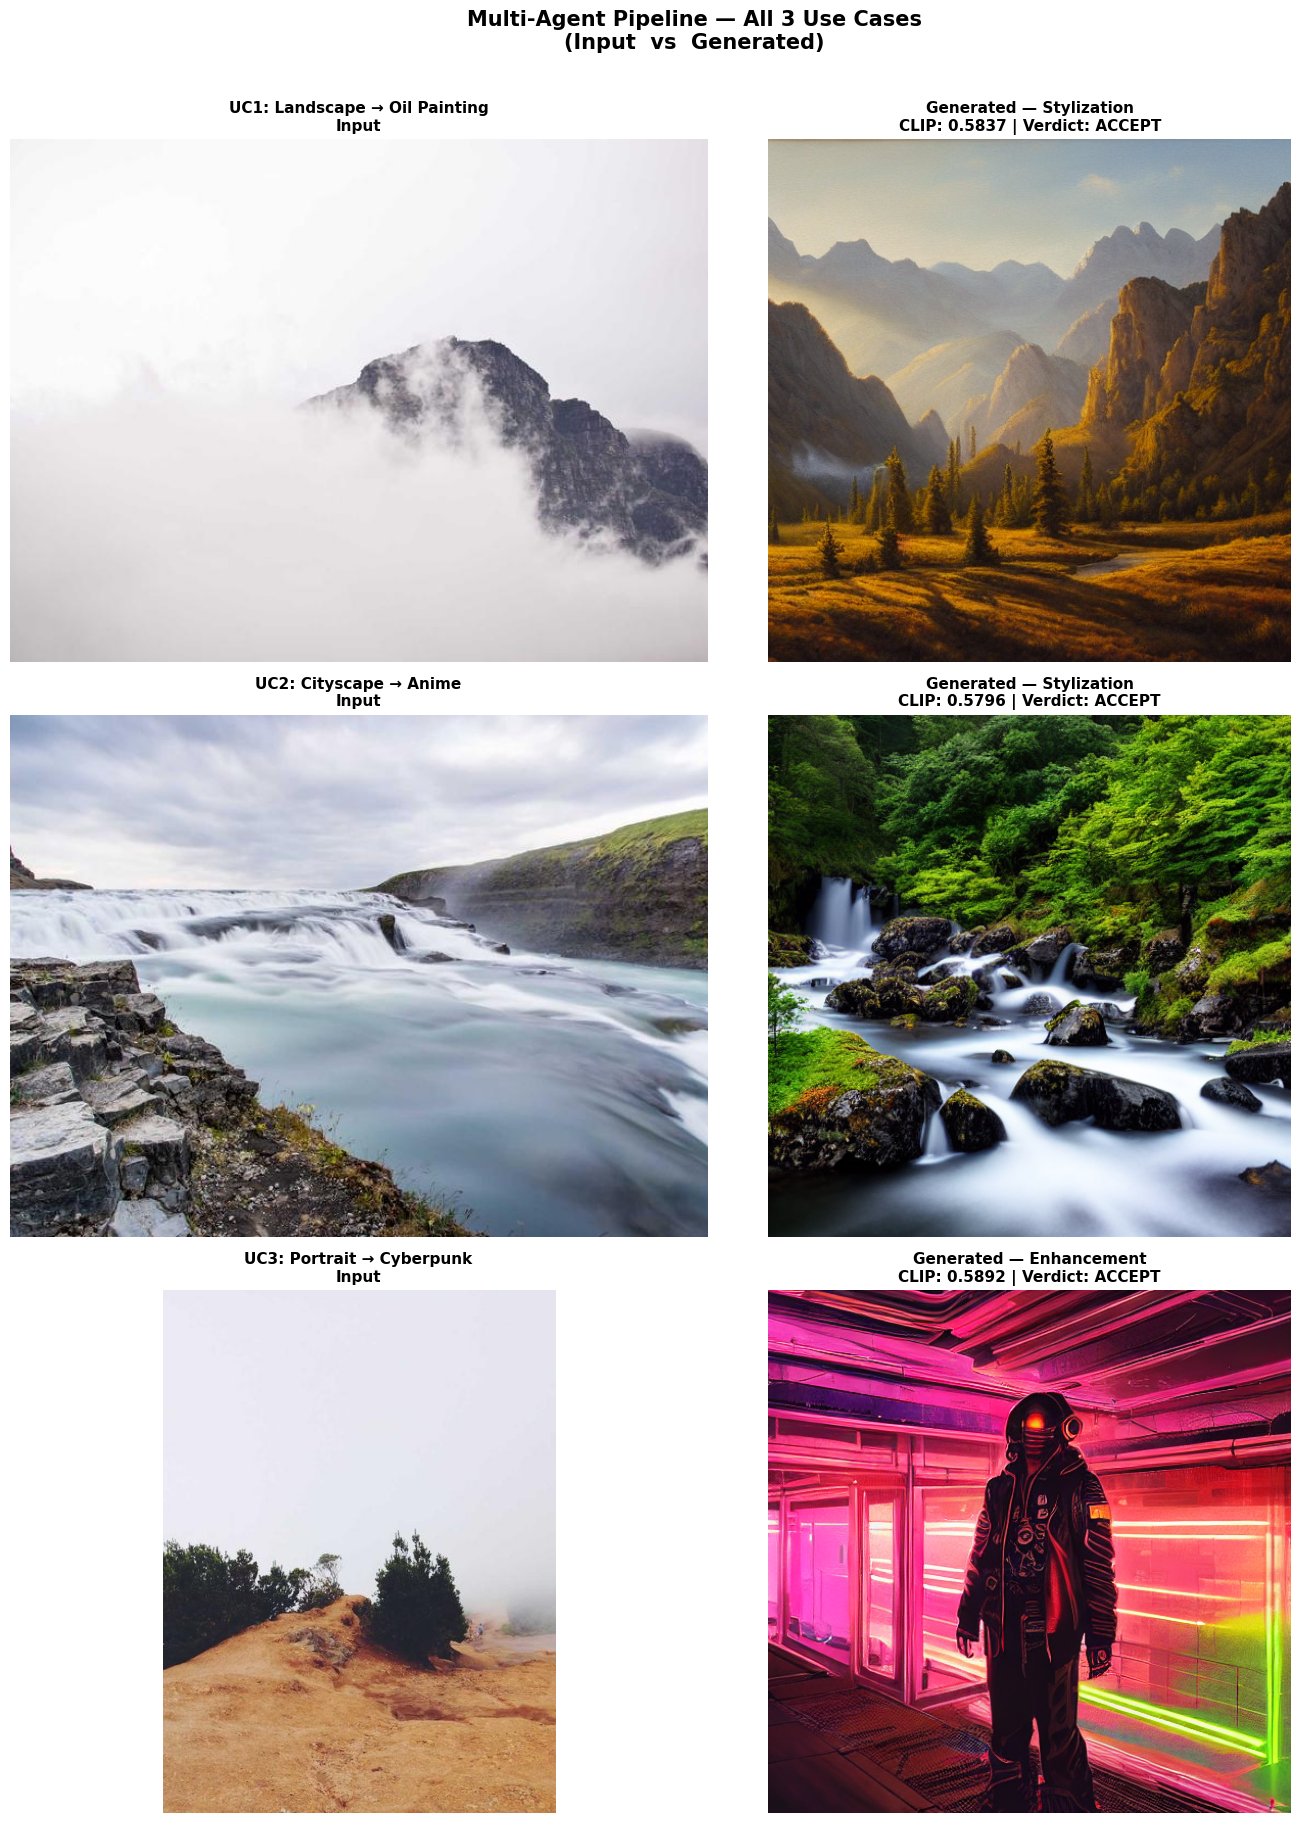

Saved → outputs/pipeline_all_use_cases.png


In [21]:
# ── Visualise all 3 pipeline results ────────────────────────────────────────
USE_CASE_LABELS = [
    "UC1: Landscape → Oil Painting",
    "UC2: Cityscape → Anime",
    "UC3: Portrait → Cyberpunk",
]

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for row, (res, label, uc) in enumerate(zip(all_results, USE_CASE_LABELS, USE_CASES)):
    ax_in, ax_out = axes[row]

    # Input image
    ax_in.imshow(Image.open(uc['image_path']))
    ax_in.set_title(f"{label}\nInput", fontsize=11, fontweight='bold')
    ax_in.axis('off')

    # Generated image or error
    if res['success'] and res['generation_output']['output_paths']:
        gen_img_path = res['generation_output']['output_paths'][0]
        ax_out.imshow(Image.open(gen_img_path))
        verdict = res['evaluation_output'].get('verdict', '?')
        clip = res['evaluation_output'].get('clip_score', 0)
        ax_out.set_title(
            f"Generated — {res['prompt_output']['transformation_type'].title()}\n"
            f"CLIP: {clip:.4f} | Verdict: {verdict.upper()}",
            fontsize=11, fontweight='bold'
        )
    else:
        ax_out.text(0.5, 0.5, f"Failed:\n{res.get('error','unknown')}",
                    ha='center', va='center', fontsize=10, color='red',
                    transform=ax_out.transAxes)
        ax_out.set_title("Generation Failed", fontsize=11)
    ax_out.axis('off')

plt.suptitle("Multi-Agent Pipeline — All 3 Use Cases\n(Input  vs  Generated)",
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "pipeline_all_use_cases.png", dpi=120, bbox_inches='tight')
plt.show()
print("Saved → outputs/pipeline_all_use_cases.png")

---
## Section 6 — Human Evaluation Rubric

Rubric for **3–5 examples** covering the 4 evaluation criteria (each scored 1–5):
- **Visual Relevance** — does the generated image relate to the input?
- **Prompt Faithfulness** — does it match the refined prompt?
- **Transformation Quality** — is the intended transformation well-executed?
- **Overall Aesthetic** — is the output visually compelling?

In [22]:
# ── Build rubric table from all results ──────────────────────────────────────
rubric_examples = []
for res, label in zip(all_results, USE_CASE_LABELS):
    if res['success'] and res['evaluation_output']:
        rubric_examples.append({
            "label": label,
            "rubric_scores": res['evaluation_output'].get('rubric_scores', {}),
            "verdict": res['evaluation_output'].get('verdict', '?'),
            "clip_score": res['evaluation_output'].get('clip_score', 0.0),
        })

# Print text table
eval_agent.print_rubric_table(rubric_examples)


                                                                 HUMAN EVALUATION RUBRIC                                                                 
---------------------------------------------------------------------------------------------------------------------------------------------------------
Example                | Visual Relevance          | Prompt Faithfulness       | Transformation Quality    | Overall Aesthetic         | CLIP   | Verdict
---------------------------------------------------------------------------------------------------------------------------------------------------------
UC1: Landscape → Oil   | 5/5                       | 5/5                       | 5/5                       | 5/5                       | 0.5837 | accept
UC2: Cityscape → Ani   | 5/5                       | 5/5                       | 5/5                       | 5/5                       | 0.5796 | accept
UC3: Portrait → Cybe   | 4/5                       | 5/5                     

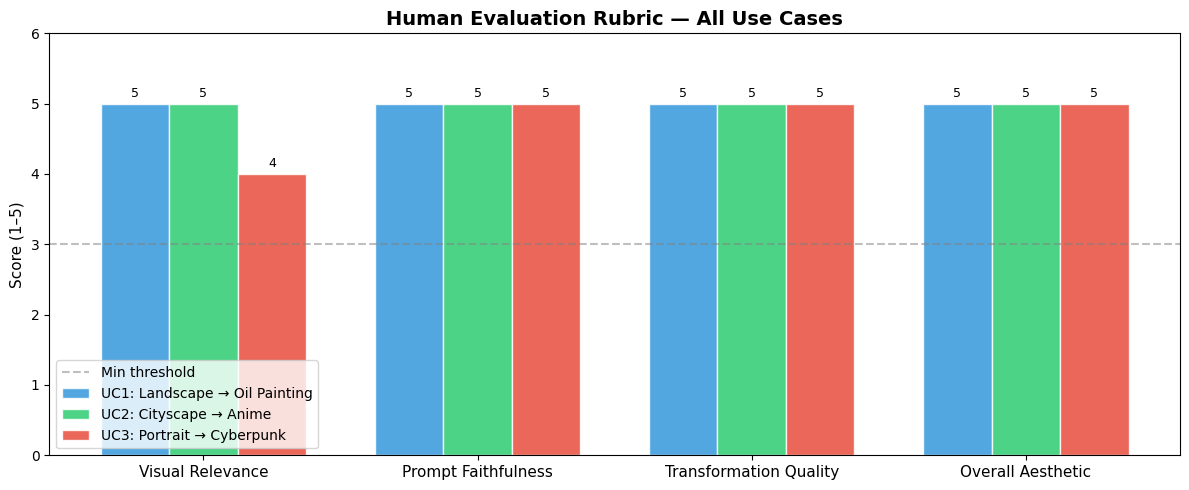

In [23]:
# ── Rubric bar chart ─────────────────────────────────────────────────────────
if rubric_examples:
    criteria = list(eval_agent.RUBRIC.keys())
    x = range(len(criteria))
    width = 0.25
    colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']

    fig, ax = plt.subplots(figsize=(12, 5))
    for i, ex in enumerate(rubric_examples):
        scores = [ex['rubric_scores'].get(c, 0) for c in criteria]
        offset = (i - len(rubric_examples)/2 + 0.5) * width
        bars = ax.bar([xi + offset for xi in x], scores, width,
                      label=ex['label'], color=colors[i], alpha=0.85,
                      edgecolor='white')
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                    str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)

    ax.set_xticks(list(x))
    ax.set_xticklabels(criteria, fontsize=11)
    ax.set_ylim(0, 6)
    ax.set_ylabel("Score (1–5)", fontsize=11)
    ax.axhline(y=3, color='gray', linestyle='--', alpha=0.5, label='Min threshold')
    ax.set_title("Human Evaluation Rubric — All Use Cases", fontsize=14, fontweight='bold')
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / "rubric_chart.png", dpi=120, bbox_inches='tight')
    plt.show()

---
## Section 7 — Summary & Architecture Diagram

### System Architecture

```
┌──────────────────────────────────────────────────────────────────┐
│              MULTIMODAL MULTI-AGENT PIPELINE                     │
│                                                                  │
│   Input Image ──────────────────────────────────────────────┐   │
│   User Instruction ──────────────────────────────────────┐  │   │
│                                                           │  │   │
│  ┌──────────────────────┐                                │  │   │
│  │  3.1 Vision Agent    │◄──────────────────────────────┘  │   │
│  │  (Gemini 1.5 Flash)  │                                   │   │
│  │  • Caption           │                                   │   │
│  │  • Objects           │                                   │   │
│  │  • Scene desc        │                                   │   │
│  │  • VQA answers       │                                   │   │
│  └──────────┬───────────┘                                   │   │
│             │  visual_output                                 │   │
│             ▼                                                │   │
│  ┌──────────────────────┐                                   │   │
│  │  3.2 Prompt Agent    │◄──────────────────────────────────┘   │
│  │  (Gemini 1.5 Flash)  │                                        │
│  │  • Rewrite prompt    │                                        │
│  │  • Enrich w/ visuals │                                        │
│  │  • Preserve intent   │                                        │
│  └──────────┬───────────┘                                        │
│             │  refined_prompt                                     │
│             ▼                                                     │
│  ┌──────────────────────┐                                        │
│  │  3.3 Generation Agent│                                        │
│  │  (Stable Diffusion   │                                        │
│  │   v1.5, diffusers)   │                                        │
│  │  • Stylization       │                                        │
│  │  • Variation         │                                        │
│  │  • Enhancement       │                                        │
│  └──────────┬───────────┘                                        │
│             │  generated_image                                    │
│             ▼                                                     │
│  ┌──────────────────────┐                                        │
│  │  3.4 Eval Agent      │◄──────────────────────── Input Image   │
│  │  (CLIP + Gemini)     │◄────────────────────── Refined Prompt  │
│  │  • CLIP similarity   │                                        │
│  │  • Human rubric      │                                        │
│  │  • Accept/Revise     │                                        │
│  └──────────────────────┘                                        │
│                                                                  │
│           3.5 Orchestrator — coordinates all agents              │
└──────────────────────────────────────────────────────────────────┘
```

In [ ]:
# ── Print final summary table ─────────────────────────────────────────────────
print("\n" + "="*70)
print("  PIPELINE EXECUTION SUMMARY".center(70))
print("="*70)
print(f"{'Use Case':<35} | {'Status':<8} | {'CLIP':<8} | {'Verdict'}")
print("-"*70)
for res, label in zip(all_results, USE_CASE_LABELS):
    status = "  OK" if res['success'] else " FAIL"
    clip = f"{res['evaluation_output']['clip_score']:.4f}" \
           if res['success'] and res['evaluation_output'] else "N/A"
    verdict = res['evaluation_output'].get('verdict', 'N/A').upper() \
              if res['success'] and res['evaluation_output'] else "N/A"
    print(f"{label:<35} | {status:<8} | {clip:<8} | {verdict}")
print("="*70)


                       PIPELINE EXECUTION SUMMARY                     
Use Case                            | Status   | CLIP     | Verdict
----------------------------------------------------------------------
UC1: Landscape → Oil Painting       |   OK     | 0.5837   | ACCEPT
UC2: Cityscape → Anime              |   OK     | 0.5796   | ACCEPT
UC3: Portrait → Cyberpunk           |   OK     | 0.5892   | ACCEPT


In [25]:
# ── Save full results to JSON ─────────────────────────────────────────────────
import json

def make_serializable(obj):
    """Convert non-serializable objects to strings."""
    if isinstance(obj, dict):
        return {k: make_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [make_serializable(v) for v in obj]
    elif isinstance(obj, Path):
        return str(obj)
    else:
        try:
            json.dumps(obj)
            return obj
        except:
            return str(obj)

results_path = OUTPUTS_DIR / "all_results.json"
with open(results_path, 'w', encoding='utf-8') as f:
    json.dump(make_serializable(all_results), f, indent=2)

print(f"Complete results saved → {results_path}")

Complete results saved → C:\Users\018315986\Desktop\Genai\Lab 2\Part_3\outputs\all_results.json
